# Modelo preditor de preço

Prevemos o ln(preço) de cada anúncio com gradient boosting, com treino, validação e teste separados por CISP inteira, para medir se o modelo funciona em áreas que nunca viu. Comparamos conjuntos de variáveis para ver se o crime melhora a previsão além do imóvel e da localização.

In [1]:
from pathlib import Path
import geopandas as gpd
import pandas as pd

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "data").is_dir()
)
DATA_DIR = PROJECT_ROOT / "data"

In [2]:
listings = pd.read_csv("../../data/listings.csv")
listings

C:\Users\rafamega\AppData\Local\Temp\ipykernel_7608\3338355115.py:1: DtypeWarning: Columns (0: host_profile_url, 1: price, 2: price_quote_checkin_date, 3: price_quote_checkout_date, 4: price_quote_raw, 5: neighborhood_overview, 6: host_since, 7: host_response_time, 8: host_response_rate, 9: host_acceptance_rate, 10: host_thumbnail_url, 11: host_neighbourhood, 12: host_verifications, 13: neighbourhood, 14: instant_bookable) have mixed types. Specify dtype option on import or set low_memory=False.
  listings = pd.read_csv("../../data/listings.csv")


,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_url,...,host_since,host_response_time,host_response_rate,host_acceptance_rate,host_thumbnail_url,host_neighbourhood,host_total_listings_count,host_verifications,neighbourhood,instant_bookable
0,1025196153924029661,https://www.airbnb.com/rooms/1025196153924029661,20260624212719,2026-06-25,city scrape,Quartos disponíveis no Recreio,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,546603190,https://www.airbnb.com/users/show/546603190,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1697400829368754530,https://www.airbnb.com/rooms/1697400829368754530,20260624212719,2026-06-25,city scrape,Casa próxima a Floresta da Tijuca,Take a break to relax in this serene oasis in ...,https://a0.muscache.com/pictures/hosting/Hosti...,737983482,https://www.airbnb.com/users/show/737983482,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,42874066,https://www.airbnb.com/rooms/42874066,20260624212719,2026-06-25,city scrape,Alugo uma vaga para sexo feminino Recreio,NaN,https://a0.muscache.com/pictures/43e779d6-58df...,341395950,https://www.airbnb.com/users/show/341395950,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1543530193994981165,https://www.airbnb.com/rooms/1543530193994981165,20260624212719,2026-06-26,previous scrape,Barra Vista maravilhosa,"Kick back and relax in this calm, stylish space.",https://a0.muscache.com/pictures/hosting/Hosti...,173836079,https://www.airbnb.com/users/show/173836079,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,831750365913119274,https://www.airbnb.com/rooms/831750365913119274,20260624212719,2026-06-25,city scrape,Suíte Rio BR,Spacious and pleasant suite in a family home.,https://a0.muscache.com/pictures/miso/Hosting-...,69238992,https://www.airbnb.com/users/show/69238992,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
179632,1651790928149305935,https://www.airbnb.com/rooms/1651790928149305935,20260330062336,2026-04-02,city scrape,Av. Atlântica | Vista Mar Incrível | Suíte Premi,"Comfortable sea-facing suite in Copacabana, on...",https://a0.muscache.com/pictures/hosting/Hosti...,357078569,https://www.airbnb.com/users/show/357078569,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
179633,1652082025241101165,https://www.airbnb.com/rooms/1652082025241101165,20260330062336,2026-04-02,city scrape,Copacabana: Praia e Conforto | 5 Hóspedes,NaN,https://a0.muscache.com/pictures/prohost-api/H...,12335830,https://www.airbnb.com/users/show/12335830,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
179634,1652148096386184589,https://www.airbnb.com/rooms/1652148096386184589,20260330062336,2026-04-02,city scrape,Amplo e bem localizado Apê em Copacabana,"Spacious apartment in Copacabana, just minutes...",https://a0.muscache.com/pictures/hosting/Hosti...,513633037,https://www.airbnb.com/users/show/513633037,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
179635,1652264749683808805,https://www.airbnb.com/rooms/1652264749683808805,20260330062336,2026-04-02,city scrape,Apartamento para trabalho e para casal,Keep it simple at this peaceful and centrally-...,https://a0.muscache.com/pictures/hosting/Hosti...,754155809,https://www.airbnb.com/users/show/754155809,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,anuncios,com_preco,com_preco_cotacao,pct_com_preco
snapshot (início),,,,
26/09/2025,43068,38670,0,89.8
28/12/2025,47087,0,0,0.0
30/03/2026,40769,39816,39811,97.7
24/06/2026,48713,44542,44542,91.4


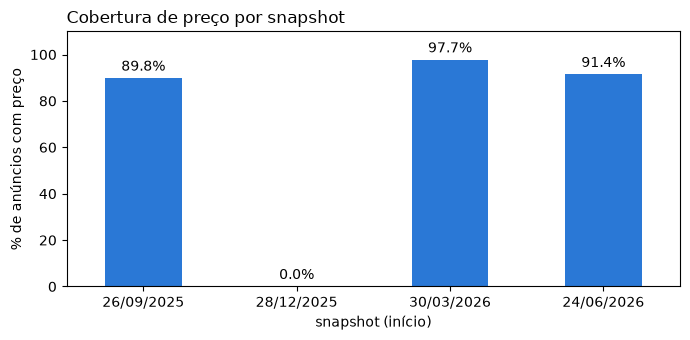

In [3]:
import matplotlib.pyplot as plt

# Cobertura de preço por snapshot: o preço vem vazio em parte dos anúncios, e em dez/25 vem 100% vazio.
cobertura_preco = listings.groupby("scrape_id").agg(
    anuncios=("id", "size"),
    com_preco=("price", "count"),
    com_preco_cotacao=("price_quote_price_per_night", "count"),
)
cobertura_preco["pct_com_preco"] = (cobertura_preco["com_preco"] / cobertura_preco["anuncios"] * 100).round(1)
cobertura_preco.index = pd.to_datetime(cobertura_preco.index.astype(str).str[:8]).strftime("%d/%m/%Y")
cobertura_preco.index.name = "snapshot (início)"
display(cobertura_preco)

ax = cobertura_preco["pct_com_preco"].plot.bar(figsize=(7, 3.5), color="#2a78d6", rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_ylim(0, 110)
ax.set_ylabel("% de anúncios com preço")
ax.set_title("Cobertura de preço por snapshot", loc="left")
plt.tight_layout()
plt.show()

In [4]:
crimes = pd.read_csv("../../data/crime_data/BaseDPEvolucaoMensalCisp.csv", encoding="latin-1", sep=";")
crimes

,cisp,mes,ano,mes_ano,aisp,risp,munic,mcirc,regiao,hom_doloso,...,cmp,cmba,ameaca,pessoas_desaparecidas,encontro_cadaver,encontro_ossada,pol_militares_mortos_serv,pol_civis_mortos_serv,registro_ocorrencias,fase
0,1,1,2003,2003m01,5,1,Rio de Janeiro,3304557,Capital,0,...,NaN,NaN,21,2,0,0,0,0,578,3
1,4,1,2003,2003m01,5,1,Rio de Janeiro,3304557,Capital,3,...,NaN,NaN,15,6,0,1,0,0,441,3
2,5,1,2003,2003m01,5,1,Rio de Janeiro,3304557,Capital,3,...,NaN,NaN,47,2,1,0,0,0,637,3
3,6,1,2003,2003m01,1,1,Rio de Janeiro,3304557,Capital,6,...,NaN,NaN,26,2,1,0,0,0,473,3
4,7,1,2003,2003m01,1,1,Rio de Janeiro,3304557,Capital,4,...,NaN,NaN,10,1,3,0,0,0,147,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38131,159,7,2026,2026m07,11,7,Cachoeiras de Macacu,3300803,Interior,0,...,3.0,0.0,21,3,0,0,0,0,148,2
38132,165,7,2026,2026m07,33,5,Mangaratiba,3302601,Interior,2,...,8.0,0.0,40,1,0,0,0,0,180,2
38133,166,7,2026,2026m07,33,5,Angra dos Reis,3300100,Interior,3,...,21.0,3.0,96,4,0,0,0,0,710,2
38134,167,7,2026,2026m07,43,5,Paraty,3303807,Capital,1,...,3.0,0.0,27,2,1,0,0,0,206,2


In [5]:
cisp = gpd.read_file(
    "../../data/shape_file/CISPshp/CISPshp/cisp.shp"
)

aisp = gpd.read_file(
    "../../data/shape_file/AISPshp/SHP/aisp.shp"
)

risp = gpd.read_file(
    "../../data/shape_file/RISPshp/RISPshp/risp.shp"
)

# População por CISP

A população de cada setor censitário (Censo 2022) é somada na CISP que contém o ponto representativo do setor. A malha de setores vem do IBGE (`RJ_setores_CD2022.zip`) e a população do Data.Rio.

In [6]:
import zipfile

POP_ZIP = DATA_DIR / "populacao" / "População_Residente_e_Domicílios__por_setor_censitário_-_Censo_2022.zip"
SETORES_ZIP = DATA_DIR / "populacao" / "RJ_setores_CD2022.zip"  # malha de setores do IBGE (Censo 2022)
MUNICIPIO_RIO = "3304557"

# População por setor censitário (Data.Rio / Censo 2022).
with zipfile.ZipFile(POP_ZIP) as z:
    csv_name = next(n for n in z.namelist() if n.endswith(".csv"))
    pop_setores = pd.read_csv(
        z.open(csv_name), sep=";", encoding="latin-1", usecols=["CD_SETOR", "Total de pessoas"]
    ).rename(columns={"Total de pessoas": "pessoas"})
assert pop_setores["CD_SETOR"].is_unique

# Polígonos dos setores da capital, com a população.
setores = gpd.read_file(f"zip://{SETORES_ZIP.as_posix()}", where=f"CD_MUN='{MUNICIPIO_RIO}'")
setores["CD_SETOR"] = setores["CD_SETOR"].astype("int64")
setores = setores[["CD_SETOR", "geometry"]].merge(pop_setores, on="CD_SETOR", how="inner", validate="one_to_one")
assert len(setores) == len(pop_setores), "setor do CSV sem polígono na malha"

# Cada setor vai para a CISP que contém o seu ponto representativo (calculado em CRS métrico).
cisp_poligonos = cisp[["cisp", "geometry"]].copy()
cisp_poligonos["cisp"] = pd.to_numeric(cisp_poligonos["cisp"]).astype(int)
pontos_setor = setores.copy()
pontos_setor["geometry"] = setores.to_crs(31983).representative_point().to_crs(cisp_poligonos.crs)
setor_cisp = gpd.sjoin(pontos_setor, cisp_poligonos, how="left", predicate="within")
assert setor_cisp["CD_SETOR"].is_unique, "ponto caiu em mais de uma CISP"

populacao_cisp = (
    setor_cisp.dropna(subset=["cisp"])
    .groupby("cisp", as_index=False)
    .agg(populacao=("pessoas", "sum"), setores=("CD_SETOR", "size"))
)
populacao_cisp["cisp"] = populacao_cisp["cisp"].astype("Int64")
area_cisp = cisp[["cisp", "areakm2"]].assign(cisp=lambda d: pd.to_numeric(d["cisp"]).astype("Int64"))
populacao_cisp = populacao_cisp.merge(area_cisp, on="cisp", how="left", validate="one_to_one")
populacao_cisp["hab_por_km2"] = populacao_cisp["populacao"] / populacao_cisp["areakm2"]

print(f"População da capital: {setores['pessoas'].sum():,} em {len(setores):,} setores")
print(f"Setores sem CISP: {setor_cisp['cisp'].isna().sum()} (população {setor_cisp.loc[setor_cisp['cisp'].isna(), 'pessoas'].sum():,})")
print(f"CISPs com população: {len(populacao_cisp)}")
display(populacao_cisp.sort_values("hab_por_km2").round(0).iloc[[0, 1, 2, -3, -2, -1]])


População da capital: 6,211,223 em 13,782 setores
Setores sem CISP: 2 (população 0)
CISPs com população: 41


,cisp,populacao,setores,areakm2,hab_por_km2
0,1,1598,19,2.0,888.0
39,43,230698,529,155.0,1486.0
38,42,204912,526,112.0,1823.0
8,12,79108,263,3.0,24721.0
9,13,61701,203,2.0,32474.0
7,11,69495,112,1.0,49639.0


# Merge Datasets

Crimes (somados por trimestre em cada CISP da capital) e anúncios (localizados na CISP por spatial join, com o trimestre dado pelo `scrape_id`) são unidos por CISP, ano e trimestre.

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Cada scrape_id é um snapshot inteiro. O trimestre vem do início do scrape:
# last_scraped atravessa a virada do trimestre e misturaria snapshots.
SNAPSHOT_PERIODS = {
    20250926170004: (2025, 3),
    20251228222302: (2025, 4),
    20260330062336: (2026, 1),
    20260624212719: (2026, 2),
}

# Níveis de gravidade, do mais grave (4) ao menos grave (1).
# Só colunas sem sobreposição: total_roubos já contém roubo_rua & cia., e
# letalidade_violenta já contém cvli. Fora: culposos (trânsito), tráfico/APF/
# apreensões (atividade policial, não incidência), desaparecidos e registro_ocorrencias.
TIER_NAMES = {
    4: "Contra a vida / sexual",
    3: "Roubos",
    2: "Violência interpessoal",
    1: "Patrimonial sem violência",
}
TIER_COLUMNS = {
    4: ["letalidade_violenta", "tentat_hom", "feminicidio", "tentativa_feminicidio",
        "estupro", "sequestro", "sequestro_relampago", "extorsao"],
    3: ["total_roubos"],
    2: ["lesao_corp_dolosa", "ameaca"],
    1: ["total_furtos", "estelionato"],
}
WEIGHTS = {4: 4, 3: 3, 2: 2, 1: 1}

ROOM_TYPE = "Entire home/apt"     # controla o tipo de imóvel
MIN_LISTINGS = 20                 # anúncios mínimos por CISP x snapshot
OUTLIER_QUANTILES = (0.01, 0.99)  # corte de preço por snapshot
N_BOOT = 2000

DENOMINADOR = "habitantes"  # "habitantes" (por 100 mil, Censo 2022) ou "km2"
ROTULO_TAXA = "por 100 mil habitantes" if DENOMINADOR == "habitantes" else "por km²"
TICKS_TAXA = [100, 300, 1000, 3000, 10000, 30000, 100000] if DENOMINADOR == "habitantes" else [0.3, 1, 3, 10, 30, 100, 300, 1000]

crime_columns = [c for cols in TIER_COLUMNS.values() for c in cols]
assert len(crime_columns) == len(set(crime_columns)), "coluna repetida entre níveis"

In [8]:
# Crimes - mês a mês por CISP (estado inteiro)
# Listings - 4 snapshots trimestrais com coordenadas
# Shapefile - CISP (traz areakm2); AISP/RISP não são necessários para o merge


def normalize_area_id(frame, columns):
    frame = frame.copy()
    for column in columns:
        frame[column] = pd.to_numeric(frame[column], errors="coerce").astype("Int64")
    return frame


# Crimes: só a capital, uma linha por CISP x mês, somados por trimestre.
crimes_rio = normalize_area_id(crimes, ["cisp"]).query("munic == 'Rio de Janeiro'")
assert not crimes_rio.duplicated(["cisp", "ano", "mes"]).any()
crimes_rio = crimes_rio.assign(trimestre=(crimes_rio["mes"] - 1) // 3 + 1)

crimes_quarterly = (
    crimes_rio.groupby(["cisp", "ano", "trimestre"], as_index=False)
    .agg(meses=("mes", "nunique"), **{c: (c, "sum") for c in crime_columns})
    .query("meses == 3")  # descarta trimestre incompleto (2026 T3 só tem julho)
    .drop(columns="meses")
)
for nivel, colunas in TIER_COLUMNS.items():
    crimes_quarterly[f"crimes_nivel{nivel}"] = crimes_quarterly[colunas].sum(axis=1)

# Listings: trimestre pelo scrape_id, coordenadas -> pontos.
listing_columns = ["id", "scrape_id", "latitude", "longitude", "price", "room_type", "accommodates", "bedrooms"]
snapshots = pd.DataFrame.from_dict(SNAPSHOT_PERIODS, orient="index", columns=["ano", "trimestre"])
listing_points = listings[listing_columns].merge(
    snapshots, left_on="scrape_id", right_index=True, how="left", validate="many_to_one"
)
assert listing_points["ano"].notna().all(), "scrape_id sem trimestre definido em SNAPSHOT_PERIODS"
listing_points = listing_points.dropna(subset=["latitude", "longitude"])
listing_points = gpd.GeoDataFrame(
    listing_points,
    geometry=gpd.points_from_xy(listing_points["longitude"], listing_points["latitude"]),
    crs="EPSG:4326",
)

# Um único sjoin com a CISP (traz a área em km²).
cisp_area = normalize_area_id(cisp, ["cisp"])[["cisp", "areakm2", "geometry"]]
listings_cisp = gpd.sjoin(
    listing_points, cisp_area, how="left", predicate="within"
).drop(columns="index_right")
assert len(listings_cisp) == len(listing_points), "sjoin duplicou linhas (polígonos sobrepostos)"
listings_cisp = normalize_area_id(pd.DataFrame(listings_cisp.drop(columns="geometry")), ["cisp"])

listings_crimes = listings_cisp.merge(
    crimes_quarterly,
    on=["cisp", "ano", "trimestre"],
    how="left",
    validate="many_to_one",
)
assert len(listings_crimes) == len(listings_cisp)

# População da CISP (Censo 2022, calculada acima): o mesmo valor nos 4 snapshots.
listings_crimes = listings_crimes.merge(populacao_cisp[["cisp", "populacao"]], on="cisp", how="left", validate="many_to_one")
assert len(listings_crimes) == len(listings_cisp)

# Taxa por nível no trimestre: por 100 mil habitantes ou por km², conforme DENOMINADOR.
base_taxa = listings_crimes["populacao"] / 100_000 if DENOMINADOR == "habitantes" else listings_crimes["areakm2"]
for nivel in TIER_COLUMNS:
    listings_crimes[f"taxa_nivel{nivel}"] = listings_crimes[f"crimes_nivel{nivel}"] / base_taxa

print(f"Dimensão de listings_crimes: {listings_crimes.shape[0]:,} linhas x {listings_crimes.shape[1]} colunas")
print(f"Anúncios fora de qualquer CISP: {listings_crimes['cisp'].isna().sum()}")
print(f"Anúncios em CISP sem população: {(listings_crimes['cisp'].notna() & listings_crimes['populacao'].isna()).sum()}")
display(
    listings_crimes.groupby(["ano", "trimestre"]).agg(
        anuncios=("id", "size"),
        com_preco=("price", "count"),
        com_crime=("crimes_nivel1", "count"),
    )
)

Dimensão de listings_crimes: 179,637 linhas x 34 colunas
Anúncios fora de qualquer CISP: 4
Anúncios em CISP sem população: 0


anuncios  com_preco  com_crime
ano  trimestre                                
2025 3             43068      38670      43067
     4             47087          0      47086
2026 1             40769      39816      40768
     2             48713      44542      48712

In [9]:
df = listings_crimes.copy()
df["preco_noite"] = pd.to_numeric(
    df["price"].astype("string").str.replace(r"[$,]", "", regex=True), errors="coerce"
).astype(float)

# Snapshot sem preço não entra na análise de preço (ex.: dez/2025 vem 100% vazio).
cobertura = df.groupby(["ano", "trimestre"])["preco_noite"].agg(anuncios="size", com_preco="count")
sem_preco = cobertura.index[cobertura["com_preco"] == 0].tolist()
if sem_preco:
    print(f"Atenção: snapshots sem nenhum preço, fora da análise: {sem_preco}")

# Só casa/apto inteiro, preço > 0, sem outliers extremos dentro de cada snapshot.
casas = df[(df["room_type"] == ROOM_TYPE) & (df["preco_noite"] > 0) & df["cisp"].notna()].copy()
por_snapshot = casas.groupby(["ano", "trimestre"])["preco_noite"]
piso = por_snapshot.transform(lambda s: s.quantile(OUTLIER_QUANTILES[0]))
teto = por_snapshot.transform(lambda s: s.quantile(OUTLIER_QUANTILES[1]))
casas = casas[(casas["preco_noite"] >= piso) & (casas["preco_noite"] <= teto)]

# Uma linha por CISP x snapshot.
taxa_cols = [f"taxa_nivel{n}" for n in sorted(TIER_COLUMNS, reverse=True)]
analise = (
    casas.groupby(["cisp", "ano", "trimestre"], as_index=False)
    .agg(
        preco_mediano=("preco_noite", "median"),
        anuncios=("id", "size"),
        areakm2=("areakm2", "first"),
        populacao=("populacao", "first"),
        **{f"crimes_nivel{n}": (f"crimes_nivel{n}", "first") for n in TIER_COLUMNS},
        **{c: (c, "first") for c in taxa_cols},
    )
    .query("anuncios >= @MIN_LISTINGS")
    .dropna(subset=taxa_cols)
    .reset_index(drop=True)
)
analise["periodo"] = "T" + analise["trimestre"].astype(str) + "/" + analise["ano"].astype(str)
assert not analise.duplicated(["cisp", "periodo"]).any()

# Os snapshots têm níveis de preço diferentes (sazonalidade/inflação). O preço relativo à
# mediana do snapshot remove esse deslocamento ao juntar os trimestres; dentro de cada
# snapshot o Spearman é idêntico ao do preço absoluto.
analise["preco_relativo"] = analise["preco_mediano"] / analise.groupby("periodo")["preco_mediano"].transform("median")

# Índice de gravidade: média ponderada do ranking percentil de cada nível.
# Ranking (e não log/z-score) porque as taxas variam em ordens de grandeza e o
# Spearman só depende da ordem de qualquer forma.
ranks = analise[taxa_cols].rank(pct=True)
analise["indice_gravidade"] = (
    sum(WEIGHTS[n] * ranks[f"taxa_nivel{n}"] for n in WEIGHTS) / sum(WEIGHTS.values())
)
analise["indice_pesos_iguais"] = ranks.mean(axis=1)

print(cobertura)
print(f"\nCISP x snapshot na análise: {len(analise)} ({analise['cisp'].nunique()} CISPs distintas)")
print(analise.groupby("periodo").agg(cisps=("cisp", "nunique"), anuncios=("anuncios", "sum")))
print("\nCorrelação (Spearman) entre as taxas de cada nível:")
display(analise[taxa_cols].corr(method="spearman").round(2))
display(analise.sort_values("indice_gravidade").head())

Atenção: snapshots sem nenhum preço, fora da análise: [(2025, 4)]
                anuncios  com_preco
ano  trimestre                     
2025 3             43068      38670
     4             47087          0
2026 1             40769      39816
     2             48713      44542

CISP x snapshot na análise: 111 (38 CISPs distintas)
         cisps  anuncios
periodo                 
T1/2026     37     32103
T2/2026     38     35380
T3/2025     36     30615

Correlação (Spearman) entre as taxas de cada nível:


,taxa_nivel4,taxa_nivel3,taxa_nivel2,taxa_nivel1
taxa_nivel4,1.00,0.48,0.54,0.45
taxa_nivel3,0.48,1.00,0.35,0.59
taxa_nivel2,0.54,0.35,1.00,0.36
taxa_nivel1,0.45,0.59,0.36,1.00


,cisp,ano,trimestre,preco_mediano,anuncios,areakm2,populacao,crimes_nivel4,crimes_nivel3,crimes_nivel2,crimes_nivel1,taxa_nivel4,taxa_nivel3,taxa_nivel2,taxa_nivel1,periodo,preco_relativo,indice_gravidade,indice_pesos_iguais
23,11,2026,2,245.03,66,1.4,69495.0,4.0,2.0,49.0,92.0,5.755810,2.877905,70.508670,132.383625,T2/2026,0.683358,0.016216,0.018018
21,11,2025,3,143.50,24,1.4,69495.0,7.0,2.0,30.0,102.0,10.072667,2.877905,43.168573,146.773149,T3/2025,0.588115,0.017117,0.018018
53,22,2025,3,175.00,29,17.3,201147.0,25.0,243.0,227.0,772.0,12.428721,120.807171,112.852789,383.798913,T3/2025,0.717213,0.093694,0.103604
99,41,2025,3,269.00,123,17.1,139544.0,21.0,181.0,228.0,881.0,15.049017,129.708192,163.389325,631.342086,T3/2025,1.102459,0.154955,0.186937
22,11,2026,1,239.00,35,1.4,69495.0,17.0,2.0,43.0,82.0,24.462192,2.877905,61.874955,117.994100,T1/2026,0.651759,0.157658,0.103604


In [10]:
import json
import re

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 0
SILHOUETTE_SAMPLE = 8000  # a silhueta é O(n²): calculada numa amostra fixa
STABILITY_BOOTSTRAPS = 5
N_BOOT_WCB = 1999

# Um registro por anúncio, com os atributos do último snapshot em que ele aparece
# (os atributos mudam pouco entre coletas: 1% a 8% dos anúncios).
imoveis = (
    listings[listings["room_type"] == ROOM_TYPE]
    .sort_values("last_scraped")
    .drop_duplicates("id", keep="last")
    .set_index("id")
)
comodidades = imoveis["amenities"].map(json.loads)


def tem(padrao):
    regex = re.compile(padrao, re.IGNORECASE)
    return comodidades.map(lambda itens: any(regex.search(item) for item in itens)).astype(int)


# Bloco 1 — porte: quanto o imóvel comporta.
X_porte = pd.DataFrame({
    "log_hospedes": np.log(imoveis["accommodates"]),
    "quartos": imoveis["bedrooms"].clip(upper=5),
    "banheiros": imoveis["bathrooms"].clip(upper=4),
    "camas": imoveis["beds"].clip(upper=8),
})
faltantes = X_porte.isna().mean()
X_porte = X_porte.fillna(X_porte.median())

# Bloco 2 — padrão: comodidades do prédio/unidade e tipo (casa x apartamento).
# Os padrões de busca evitam falsos positivos ("Dishwasher", "Pool table", "Pool view", estacionamento de rua).
CASAS = ["Entire home", "Entire villa", "Entire guesthouse", "Entire cottage", "Entire bungalow", "Entire townhouse"]
X_padrao = pd.DataFrame({
    "log_n_comodidades": np.log1p(comodidades.map(len)),
    "ar_condicionado": tem(r"air conditioning|\bac\b"),
    "elevador": tem(r"\belevator\b"),
    "lavadora": tem(r"\bwasher\b"),
    "piscina": tem(r"\bpool\b(?! table| view)"),
    "academia": tem(r"\bgym\b"),
    "estacionamento": tem(r"(parking|garage).*on premises"),
    "area_de_trabalho": tem(r"dedicated workspace"),
    "churrasqueira": tem(r"\bbbq\b|\bgrill\b"),
    "sauna_ou_jacuzzi": tem(r"sauna|hot tub|jacuzzi"),
    "casa": imoveis["property_type"].isin(CASAS).astype(int),
})

# Comodidades que embutem a LOCALIZAÇÃO ficam de fora do agrupamento (ver texto acima).
EXCLUIDAS_LOCALIZACAO = {
    "acesso à praia (Beach access)": r"beach access",
    "vista para o mar/oceano": r"sea view|ocean view",
    "frente ao mar/à água": r"beachfront|waterfront",
    "vista da montanha": r"mountain view",
    "vista do skyline": r"skyline",
}
excluidas = pd.Series({nome: tem(padrao).mean() for nome, padrao in EXCLUIDAS_LOCALIZACAO.items()})

print(f"Anúncios únicos de casa/apto inteiro: {len(imoveis):,}")
print(f"Dados faltantes no bloco de porte (imputados pela mediana):\n{faltantes.round(3).to_string()}\n")
print("Prevalência das variáveis do bloco de padrão:")
display(X_padrao.drop(columns="log_n_comodidades").mean().round(2).to_frame("prevalência").T)
print("Comodidades EXCLUÍDAS por embutirem localização (prevalência):")
display(excluidas.round(3).to_frame("prevalência").T)

Anúncios únicos de casa/apto inteiro: 49,672
Dados faltantes no bloco de porte (imputados pela mediana):
log_hospedes    0.000
quartos         0.039
banheiros       0.138
camas           0.104

Prevalência das variáveis do bloco de padrão:


,ar_condicionado,elevador,lavadora,piscina,academia,estacionamento,area_de_trabalho,churrasqueira,sauna_ou_jacuzzi,casa
prevalência,0.9,0.5,0.58,0.24,0.14,0.4,0.45,0.12,0.11,0.07


Comodidades EXCLUÍDAS por embutirem localização (prevalência):


,acesso à praia (Beach access),vista para o mar/oceano,frente ao mar/à água,vista da montanha,vista do skyline
prevalência,0.412,0.053,0.107,0.058,0.06


## Dados do modelo e divisão em treino, validação e teste

Cada CISP fica inteira em um só grupo. O crime é medido por CISP, então um sorteio aleatório de anúncios deixaria o modelo reconhecer a CISP pelo valor do crime e inflaria o resultado.

In [11]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GroupShuffleSplit

SEED = 0
TEST_FRAC, VAL_FRAC = 0.2, 0.2  # frações de CISPs inteiras (não de anúncios)
N_SPLITS = 20                   # repetições do protocolo com sorteios diferentes de CISPs

# Uma linha por anúncio x snapshot, nas mesmas CISP x snapshot da análise (casas, sem outliers, >= MIN_LISTINGS).
base = (
    casas[["id", "cisp", "ano", "trimestre", "preco_noite", "latitude", "longitude"]]
    .merge(analise[["cisp", "ano", "trimestre", "periodo"] + taxa_cols],
           on=["cisp", "ano", "trimestre"], how="inner", validate="many_to_one")
    .join(X_porte, on="id").join(X_padrao, on="id")
)
base["cisp"] = base["cisp"].astype(int)
periodos_ordem = sorted(base["periodo"].unique(), key=lambda p: (p[-4:], p[:2]))
base["snapshot"] = base["periodo"].map({p: i for i, p in enumerate(periodos_ordem)})
base["y"] = np.log(base["preco_noite"])

IMOVEL = list(X_porte.columns) + list(X_padrao.columns) + ["snapshot"]
LOCAL = ["latitude", "longitude"]
CRIME = list(taxa_cols)  # taxa de crime por nível, da CISP naquele trimestre
CONJUNTOS = {
    "Imóvel": IMOVEL,
    "Imóvel + crime": IMOVEL + CRIME,
    "Imóvel + localização": IMOVEL + LOCAL,
    "Imóvel + localização + crime": IMOVEL + LOCAL + CRIME,
}
assert base[IMOVEL + LOCAL + CRIME + ["y"]].notna().all().all()
print(f"{len(base):,} anúncios x snapshot em {base['cisp'].nunique()} CISPs, snapshots: {periodos_ordem}")


def dividir(seed):
    """Treino, validação e teste com CISPs disjuntas: o modelo é avaliado em áreas que nunca viu."""
    grupos = base["cisp"].to_numpy()
    resto, teste = next(GroupShuffleSplit(1, test_size=TEST_FRAC, random_state=seed).split(base, groups=grupos))
    tr, va = next(GroupShuffleSplit(1, test_size=VAL_FRAC / (1 - TEST_FRAC), random_state=seed).split(base.iloc[resto], groups=grupos[resto]))
    return resto[tr], resto[va], teste


treino, validacao, teste = dividir(SEED)
for nome, idx in [("treino", treino), ("validação", validacao), ("teste", teste)]:
    print(f"{nome:10s} {len(idx):>7,} anúncios, {base.iloc[idx]['cisp'].nunique():>2} CISPs")
assert not (set(base.iloc[treino]["cisp"]) & set(base.iloc[validacao]["cisp"]) & set(base.iloc[teste]["cisp"]))
assert not (set(base.iloc[treino]["cisp"]) & set(base.iloc[teste]["cisp"]))
assert not (set(base.iloc[validacao]["cisp"]) & set(base.iloc[teste]["cisp"]))


98,098 anúncios x snapshot em 38 CISPs, snapshots: ['T3/2025', 'T1/2026', 'T2/2026']
treino      57,312 anúncios, 22 CISPs
validação   23,448 anúncios,  8 CISPs
teste       17,338 anúncios,  8 CISPs


## Treino, validação e teste

Os hiperparâmetros são escolhidos na validação. O teste é usado uma vez, com o modelo refeito em treino + validação. A referência é a mediana do log-preço de cada snapshot.

In [12]:
def metricas(y_log, pred_log):
    y, p = np.exp(y_log), np.exp(pred_log)
    return {
        "r2_log": r2_score(y_log, pred_log),
        "mae_reais": mean_absolute_error(y, p),
        "erro_mediano_pct": float(np.median(np.abs(p - y) / y) * 100),
    }


def ajustar(cols, idx, params):
    modelo = HistGradientBoostingRegressor(max_iter=200, early_stopping=False, random_state=SEED, **params)
    return modelo.fit(base.iloc[idx][cols], base.iloc[idx]["y"])


def baseline(idx_fit, idx_eval):
    """Sem modelo: mediana do log-preço de cada snapshot no treino."""
    mediana = base.iloc[idx_fit].groupby("snapshot")["y"].median()
    return base.iloc[idx_eval]["snapshot"].map(mediana).to_numpy()


GRADE = [
    {"max_depth": d, "learning_rate": lr, "min_samples_leaf": leaf}
    for d in (3, 6) for lr in (0.05, 0.1) for leaf in (100, 500)
]

# 1) Escolha dos hiperparâmetros na VALIDAÇÃO; o TESTE só é usado uma vez, com o modelo refeito em treino + validação.
linhas = []
melhores = {}
y_val, y_teste = base.iloc[validacao]["y"].to_numpy(), base.iloc[teste]["y"].to_numpy()
for nome, cols in CONJUNTOS.items():
    ranking = [
        (r2_score(y_val, ajustar(cols, treino, p).predict(base.iloc[validacao][cols])), p) for p in GRADE
    ]
    r2_val, melhor = max(ranking, key=lambda t: t[0])
    melhores[nome] = melhor
    final = ajustar(cols, np.concatenate([treino, validacao]), melhor)
    m = metricas(y_teste, final.predict(base.iloc[teste][cols]))
    linhas.append({"conjunto": nome, "r2_validacao": r2_val, **{f"teste_{k}": v for k, v in m.items()}})
m0 = metricas(y_teste, baseline(np.concatenate([treino, validacao]), teste))
linhas.insert(0, {"conjunto": "Sem modelo (mediana do snapshot)", "r2_validacao": np.nan, **{f"teste_{k}": v for k, v in m0.items()}})
resultado_split = pd.DataFrame(linhas).set_index("conjunto")
display(resultado_split.round(3))
print("Hiperparâmetros escolhidos na validação:")
for nome, p in melhores.items():
    print(f"  {nome}: {p}")


,r2_validacao,teste_r2_log,teste_mae_reais,teste_erro_mediano_pct
conjunto,,,,
Sem modelo (mediana do snapshot),NaN,-0.623,620.298,45.031
Imóvel,0.511,0.196,482.581,35.044
Imóvel + crime,0.565,0.291,462.001,32.728
Imóvel + localização,0.546,0.343,445.861,30.975
Imóvel + localização + crime,0.558,0.344,447.537,31.397


Hiperparâmetros escolhidos na validação:
  Imóvel: {'max_depth': 6, 'learning_rate': 0.05, 'min_samples_leaf': 500}
  Imóvel + crime: {'max_depth': 6, 'learning_rate': 0.05, 'min_samples_leaf': 100}
  Imóvel + localização: {'max_depth': 6, 'learning_rate': 0.05, 'min_samples_leaf': 500}
  Imóvel + localização + crime: {'max_depth': 6, 'learning_rate': 0.05, 'min_samples_leaf': 100}


## Estabilidade e efeito do crime

O mesmo protocolo é repetido com vários sorteios de CISPs, porque com poucas CISPs um único teste varia muito.

,r2_medio,r2_dp,mae_reais,erro_mediano_pct
conjunto,,,,
Sem modelo (mediana do snapshot),-0.042,0.166,377.183,51.963
Imóvel,0.347,0.117,312.576,41.420
Imóvel + crime,0.422,0.064,284.276,30.736
Imóvel + localização,0.461,0.059,282.300,32.235
Imóvel + localização + crime,0.453,0.052,280.589,31.135


Ganho de R² ao acrescentar o crime, em 20 sorteios de CISPs:


,ganho_medio,ganho_mediano,sorteios_com_ganho,pior,melhor
Imóvel → Imóvel + crime,0.0750,0.0729,15,-0.0440,0.2465
Imóvel + localização → + crime,-0.0074,-0.0098,7,-0.0369,0.0323


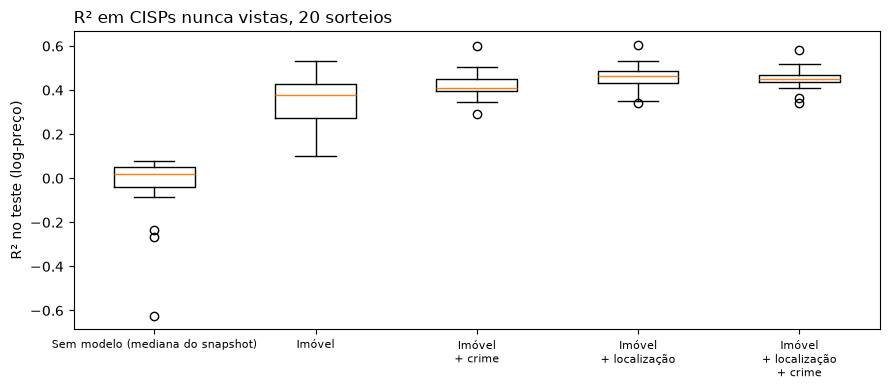

In [13]:
# 2) Com ~38 CISPs, um único sorteio de teste (~8 CISPs) é instável. Repete o protocolo com vários sorteios,
# mantendo os hiperparâmetros acima, para ver a variação e se o crime ajuda de forma consistente.
registros = []
for s in range(N_SPLITS):
    tr, va, te = dividir(s)
    fit_idx = np.concatenate([tr, va])
    for nome, cols in CONJUNTOS.items():
        m = metricas(base.iloc[te]["y"].to_numpy(), ajustar(cols, fit_idx, melhores[nome]).predict(base.iloc[te][cols]))
        registros.append({"split": s, "conjunto": nome, **m})
    m = metricas(base.iloc[te]["y"].to_numpy(), baseline(fit_idx, te))
    registros.append({"split": s, "conjunto": "Sem modelo (mediana do snapshot)", **m})
repetido = pd.DataFrame(registros)

resumo = repetido.groupby("conjunto").agg(
    r2_medio=("r2_log", "mean"), r2_dp=("r2_log", "std"),
    mae_reais=("mae_reais", "mean"), erro_mediano_pct=("erro_mediano_pct", "mean"),
).loc[["Sem modelo (mediana do snapshot)"] + list(CONJUNTOS)]
display(resumo.round(3))

# Efeito de acrescentar o crime, em cada sorteio.
wide = repetido.pivot(index="split", columns="conjunto", values="r2_log")
ganhos = pd.DataFrame({
    "Imóvel → Imóvel + crime": wide["Imóvel + crime"] - wide["Imóvel"],
    "Imóvel + localização → + crime": wide["Imóvel + localização + crime"] - wide["Imóvel + localização"],
})
print(f"Ganho de R² ao acrescentar o crime, em {N_SPLITS} sorteios de CISPs:")
display(pd.DataFrame({
    "ganho_medio": ganhos.mean(), "ganho_mediano": ganhos.median(),
    "sorteios_com_ganho": (ganhos > 0).sum(), "pior": ganhos.min(), "melhor": ganhos.max(),
}).round(4))

fig, ax = plt.subplots(figsize=(9, 4))
ordem = ["Sem modelo (mediana do snapshot)"] + list(CONJUNTOS)
ax.boxplot([wide[c] for c in ordem])
ax.set_xticklabels([c.replace(" + ", "\n+ ") for c in ordem], fontsize=8)
ax.set_ylabel("R² no teste (log-preço)")
ax.set_title(f"R² em CISPs nunca vistas, {N_SPLITS} sorteios", loc="left")
plt.tight_layout()
plt.show()


## Importância do crime

In [14]:
# 3) Quanto cada variável de crime importa para a previsão (modelo com imóvel + localização + crime, sorteio principal).
cols = CONJUNTOS["Imóvel + localização + crime"]
modelo_final = ajustar(cols, np.concatenate([treino, validacao]), melhores["Imóvel + localização + crime"])
imp = permutation_importance(
    modelo_final, base.iloc[teste][cols], base.iloc[teste]["y"], n_repeats=5, random_state=SEED, scoring="r2"
)
importancia = pd.Series(imp.importances_mean, index=cols).sort_values(ascending=False)
print("Queda de R² no teste ao embaralhar cada variável (maior = mais importante):")
display(importancia.head(10).round(4).to_frame("queda_r2"))
print(f"Soma das 4 taxas de crime: {importancia[CRIME].sum():.4f}")


Queda de R² no teste ao embaralhar cada variável (maior = mais importante):


,queda_r2
snapshot,0.1325
quartos,0.1097
banheiros,0.0614
latitude,0.0613
log_n_comodidades,0.0449
piscina,0.0276
log_hospedes,0.0202
estacionamento,0.0100
taxa_nivel1,0.0080
longitude,0.0059


Soma das 4 taxas de crime: 0.0106


## Leitura dos resultados

Em 20 sorteios de CISPs, o modelo só com o imóvel chega a R² médio de 0,35 no teste (erro mediano de 41%). Acrescentar o crime sobe o R² para 0,42, em 15 dos 20 sorteios, e acrescentar a localização (latitude e longitude) sobe para 0,46. Com a localização já no modelo, o crime não ajuda mais (ganho médio de −0,007, em só 7 dos 20 sorteios), e a importância das 4 taxas de crime somadas é de 0,011 de R². O crime melhora a previsão enquanto é o único sinal do lugar e deixa de melhorar quando a localização entra, o que indica que ele funciona como um indicador de área e não como um fator próprio de preço. Os números variam bastante entre sorteios (o sorteio principal deu R² de 0,34 com localização contra 0,46 na média), porque são só 38 CISPs.